In [18]:
#
#
#
import arslabrobotics as ar
import numpy as np

data = np.loadtxt("motor_data.txt")
(rows, _) = data.shape

arx = ar.identification.ARXSolver(data, 6, 0)
(a, b) = arx.solve()
# y(k) + a1 * y(k-1)= b0 * u(k) 

print(a,b)

[0.33767920649257843, 0.030351851269517838, -0.06991691710236897, -0.2554768900516606, -0.27373688677420616, -0.2502839090473205] [21.62500531307648]


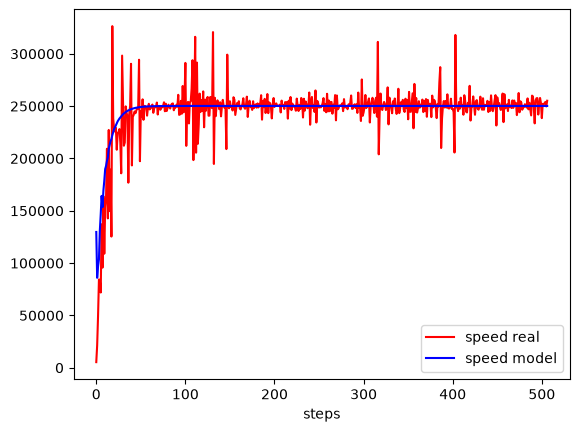

In [19]:
dp = ar.data.DataPlotter()
dp.set_x("steps")
dp.add_y("speed_r", "speed real")
dp.add_y("speed_m", "speed model")

system = ar.identification.ARXModel(a, b)
t = 0
for i in range(rows):
    u = data[i, 0]
    y = system.evaluate(u)
    dp.append_x(t)
    dp.append_y("speed_m", y)
    dp.append_y("speed_r", data[i,1])
    t += 1

dp.plot()

